# Generative Project — Milestone 2

This notebook connects the frozen **CLIP image embeddings** from Milestone 1 to a pretrained **GPT-2** decoder through a trained **mapping network** (prefix conditioning) and trains it on the train split.

```
CLIP embedding (512) ──► mapping network (MLP, trained) ──► prefix: 10 × 768 ──┐
caption ──► GPT-2 tokenizer ──► token ids ──► GPT-2 token embeddings ──────────┴─► GPT-2 (frozen) ──► next-token loss
```
Also, this notebook generates a caption from a CLIP image embedding with three decoding strategies : greedy, beam search(5 beams), and nucleus sampling(top-p = 0.9). No_repeat optionally blocks repeated n-grams.

**Steps**
0. Setup
1. Load the Milestone 1 outputs (`coco_captions_clean.csv`, `clip_image_embs.pt`)
2. Tokenize captions (end-of-sequence token, padding, label masking)
3. Build the train / val DataLoaders
4. Define the model
5. Train with validation loss and early stopping
6. Save the training log, loss curve, and checkpoint
7. Sanity check
8. Save the result
9. Load the trained model
10. Caption Generation
11. Initial Test
12. Baseline Test with Repetition Control

**Outputs :** `mapping_net.pt`, `training_log.csv`, `loss_curve.png`, `training_summary.json`, `generated_captions.csv`,`caption_samples.png`

## 0. Setup

In [1]:
import os, json, time, math, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)
if device == 'cuda':
    print(torch.cuda.get_device_name(0))

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device: cuda | torch 2.14.1+cu130
Tesla T4


In [2]:
# ===== Configuration =====
DATA_SOURCE = 'drive'   # 'drive' (Milestone 1 output folder) or 'github' (data/ folder of the repo)

DRIVE_DIR = '/content/drive/MyDrive/IE7615_generative'           # Milestone 1 outputs
REPO_URL  = 'https://github.com/ljmljm7/ie7615-generative-project'
OUT_DIR   = f'{DRIVE_DIR}/milestone2'                             # Milestone 2 outputs

CSV_NAME, EMB_NAME = 'coco_captions_clean.csv', 'clip_image_embs.pt'

# Model
GPT_NAME   = 'gpt2'
PREFIX_LEN = 10        # number of prefix vectors (ClipCap default)
CLIP_DIM   = 512
DROPOUT    = 0.1
FREEZE_GPT = True      # baseline: only the mapping network is trained
NORMALIZE_EMB = True   # L2-normalize CLIP embeddings before the mapping network

# Data / training
MAX_LEN    = 30        # caption tokens incl. end-of-sequence (covers 99.9% of captions)
BATCH_SIZE = 32
EPOCHS     = 20
LR         = 2e-4
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 100
GRAD_CLIP  = 1.0
PATIENCE   = 3         # early stopping on validation loss

In [3]:
from google.colab import drive
drive.mount('/content/drive')

if DATA_SOURCE == 'github':
    if not os.path.exists('/content/repo'):
        !git clone -q {REPO_URL} /content/repo
    DATA_DIR = '/content/repo/data'
else:
    DATA_DIR = DRIVE_DIR

os.makedirs(OUT_DIR, exist_ok=True)
print('data from :', DATA_DIR, os.listdir(DATA_DIR))
print('outputs to:', OUT_DIR)

Mounted at /content/drive
data from : /content/drive/MyDrive/IE7615_generative ['clip_image_embs.pt.old', 'coco_captions_clean.csv', 'data_summary.json', 'clip_image_embs.pt', 'milestone2']
outputs to: /content/drive/MyDrive/IE7615_generative/milestone2


## 1. Load the Milestone 1 outputs
- `coco_captions_clean.csv`: 5,000 cleaned captions with the image-level split
- `clip_image_embs.pt`: `{'ids': [...], 'embs': tensor(1000, 512)}`

`weights_only=False` is needed because the saved ids are NumPy integers.

In [4]:
df = pd.read_csv(f'{DATA_DIR}/{CSV_NAME}')
saved = torch.load(f'{DATA_DIR}/{EMB_NAME}', map_location='cpu', weights_only=False)

emb_ids = [int(i) for i in saved['ids']]
embs = saved['embs'].float()

if NORMALIZE_EMB:
    embs = embs / embs.norm(dim=-1, keepdim=True)
id2row = {iid: k for k, iid in enumerate(emb_ids)}

print('captions  :', len(df), '| images in CSV:', df['image_id'].nunique())
print('embeddings:', tuple(embs.shape))

missing = set(df['image_id']) - set(id2row)
assert not missing, f'{len(missing)} CSV images have no embedding'
assert embs.shape[1] == CLIP_DIM
print('every caption has a matching image embedding ✓')
print(df['split'].value_counts().reindex(['train', 'val', 'test']).to_string())

captions  : 5000 | images in CSV: 1000
embeddings: (1000, 512)
every caption has a matching image embedding ✓
split
train    4000
val       500
test      500


## 2. Tokenize captions
- GPT-2 has no padding token, so the end-of-sequence token is reused for padding.
- Each caption ends with the end-of-sequence token, so the model learns when to stop.
- Padding positions get label `-100` and are ignored by the loss. The prefix positions are masked inside the model.

In [5]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(GPT_NAME)
tokenizer.pad_token = tokenizer.eos_token

def encode(captions):
    enc = tokenizer([c + tokenizer.eos_token for c in captions],
                    max_length=MAX_LEN, truncation=True, padding='max_length', return_tensors='pt')
    labels = enc['input_ids'].clone()
    labels[enc['attention_mask'] == 0] = -100     # padding -> ignored
    return enc['input_ids'], enc['attention_mask'], labels

full_len = [len(tokenizer(c + tokenizer.eos_token)['input_ids']) for c in df['caption']]
print(f'captions longer than MAX_LEN={MAX_LEN}: {sum(l > MAX_LEN for l in full_len)} (truncated)')

ex_ids, ex_mask, ex_lab = encode([df['caption'].iloc[0]])
print('\nexample   :', df['caption'].iloc[0])
print('input_ids :', ex_ids[0][:16].tolist(), '...')
print('labels    :', ex_lab[0][:16].tolist(), '...')
print('tokens    :', tokenizer.convert_ids_to_tokens(ex_ids[0][ex_mask[0] == 1].tolist()))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

captions longer than MAX_LEN=30: 4 (truncated)

example   : a bedroom with a bed and small table near by
input_ids : [64, 14043, 351, 257, 3996, 290, 1402, 3084, 1474, 416, 50256, 50256, 50256, 50256, 50256, 50256] ...
labels    : [64, 14043, 351, 257, 3996, 290, 1402, 3084, 1474, 416, 50256, -100, -100, -100, -100, -100] ...
tokens    : ['a', 'Ġbedroom', 'Ġwith', 'Ġa', 'Ġbed', 'Ġand', 'Ġsmall', 'Ġtable', 'Ġnear', 'Ġby', '<|endoftext|>']


## 3. Datasets and DataLoaders
Each row is one image–caption pair: (CLIP embedding, token ids, attention mask, labels).
Only `train` is used for training; `val` tracks the validation loss. `test` is left for caption generation.

In [6]:
from torch.utils.data import TensorDataset, DataLoader

def make_dataset(split):
    part = df[df['split'] == split].reset_index(drop=True)
    rows = torch.tensor([id2row[i] for i in part['image_id']])
    ids, mask, labels = encode(part['caption'].tolist())
    return TensorDataset(embs[rows], ids, mask, labels)

train_ds, val_ds = make_dataset('train'), make_dataset('val')
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f'train pairs: {len(train_ds):,} ({len(train_loader)} batches)')
print(f'val pairs  : {len(val_ds):,} ({len(val_loader)} batches)')

train pairs: 4,000 (125 batches)
val pairs  : 500 (16 batches)


## 4. Model: CLIP prefix → GPT-2
Written to `clipcap_model.py` so the generation part can import the same model.

- **MappingNetwork**: MLP `512 → 3,840 → 7,680`, reshaped to 10 prefix vectors of 768 (GPT-2 width)
- **ClipCaptionModel**: puts the prefix in front of the caption token embeddings and runs GPT-2 on `inputs_embeds`.
  Prefix positions are added to the labels as `-100`; GPT-2 shifts the labels internally for next-token prediction (teacher forcing).

In [7]:
import torch
import torch.nn as nn
from transformers import GPT2LMHeadModel


class MappingNetwork(nn.Module):
    """MLP that maps one CLIP image embedding to `prefix_len` GPT-2 input vectors."""

    def __init__(self, clip_dim=512, gpt_dim=768, prefix_len=10, dropout=0.1):
        super().__init__()
        self.prefix_len, self.gpt_dim = prefix_len, gpt_dim
        hidden = gpt_dim * prefix_len // 2
        self.mlp = nn.Sequential(
            nn.Linear(clip_dim, hidden), nn.Tanh(), nn.Dropout(dropout),
            nn.Linear(hidden, gpt_dim * prefix_len),
        )

    def forward(self, clip_emb):                        # (B, 512)
        return self.mlp(clip_emb).view(-1, self.prefix_len, self.gpt_dim)   # (B, P, 768)


class ClipCaptionModel(nn.Module):
    """Prefix conditioning: [prefix vectors] + [caption token embeddings] -> GPT-2."""

    def __init__(self, prefix_len=10, clip_dim=512, gpt_name='gpt2', freeze_gpt=True, dropout=0.1):
        super().__init__()
        self.gpt = GPT2LMHeadModel.from_pretrained(gpt_name)
        self.prefix_len, self.freeze_gpt = prefix_len, freeze_gpt
        self.mapping = MappingNetwork(clip_dim, self.gpt.config.n_embd, prefix_len, dropout)
        self.config = dict(prefix_len=prefix_len, clip_dim=clip_dim, gpt_name=gpt_name,
                           freeze_gpt=freeze_gpt, dropout=dropout)
        if freeze_gpt:
            for p in self.gpt.parameters():
                p.requires_grad = False

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_gpt:
            self.gpt.eval()                              # frozen GPT-2 stays in eval mode
        return self

    def get_prefix(self, clip_emb):
        """(B, 512) -> (B, prefix_len, 768). Used for caption generation."""
        return self.mapping(clip_emb)

    def forward(self, clip_emb, input_ids, attention_mask, labels=None):
        prefix = self.mapping(clip_emb)                                  # (B, P, 768)
        tokens = self.gpt.get_input_embeddings()(input_ids)              # (B, T, 768)
        embeds = torch.cat([prefix, tokens], dim=1)                      # (B, P+T, 768)
        prefix_mask = torch.ones(prefix.shape[:2], dtype=attention_mask.dtype, device=attention_mask.device)
        mask = torch.cat([prefix_mask, attention_mask], dim=1)
        if labels is not None:                                           # prefix positions -> ignored
            ignore = torch.full((labels.size(0), self.prefix_len), -100, dtype=labels.dtype, device=labels.device)
            labels = torch.cat([ignore, labels], dim=1)
        return self.gpt(inputs_embeds=embeds, attention_mask=mask, labels=labels)   # .loss, .logits

    def checkpoint(self, **extra):
        return {'config': self.config,
                'mapping': self.mapping.state_dict(),
                'gpt': None if self.freeze_gpt else self.gpt.state_dict(),
                **extra}


def load_model(path, device='cpu'):
    """Rebuild the model from a checkpoint saved by the training notebook."""
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model = ClipCaptionModel(**ckpt['config'])
    model.mapping.load_state_dict(ckpt['mapping'])
    if ckpt['gpt'] is not None:
        model.gpt.load_state_dict(ckpt['gpt'])
    return model.to(device).eval(), ckpt

In [8]:
model = ClipCaptionModel(PREFIX_LEN, CLIP_DIM, GPT_NAME, FREEZE_GPT, DROPOUT).to(device)

n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f'trainable parameters: {n_train:,} (mapping network)')
print(f'total parameters    : {n_total:,}')

# shape check on one batch
e, ids, mask, lab = [t.to(device) for t in next(iter(train_loader))]
with torch.no_grad():
    out = model(e, ids, mask, lab)
    prefix_shape = tuple(model.get_prefix(e).shape)
print('\nprefix:', prefix_shape, '| logits:', tuple(out.logits.shape))
print(f'initial loss: {out.loss.item():.3f}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

trainable parameters: 31,468,800 (mapping network)
total parameters    : 155,908,608


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.



prefix: (32, 10, 768) | logits: (32, 40, 50257)
initial loss: 9.268


## 5. Training
AdamW on the mapping network only, linear warmup then linear decay, gradient clipping.
After every epoch the validation loss is computed without updating the model; the best epoch is saved and training stops early if it does not improve for `PATIENCE` epochs.

In [9]:
from torch.optim.lr_scheduler import LambdaLR

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(params, lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * len(train_loader)

def lr_lambda(step):
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    return max(0.0, (total_steps - step) / max(1, total_steps - WARMUP_STEPS))
scheduler = LambdaLR(optimizer, lr_lambda)

@torch.no_grad()
def evaluate(loader):
    model.eval()
    total, n = 0.0, 0
    for e, ids, mask, lab in loader:
        e, ids, mask, lab = e.to(device), ids.to(device), mask.to(device), lab.to(device)
        total += model(e, ids, mask, lab).loss.item() * e.size(0)
        n += e.size(0)
    return total / n

In [10]:
CKPT_PATH = f'{OUT_DIR}/mapping_net.pt'
log, best_val, best_epoch, wait = [], float('inf'), 0, 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, run_loss, n = time.time(), 0.0, 0
    for e, ids, mask, lab in train_loader:
        e, ids, mask, lab = e.to(device), ids.to(device), mask.to(device), lab.to(device)
        loss = model(e, ids, mask, lab).loss        # forward + loss
        optimizer.zero_grad()
        loss.backward()                             # backward
        torch.nn.utils.clip_grad_norm_(params, GRAD_CLIP)
        optimizer.step()                            # update
        scheduler.step()
        run_loss += loss.item() * e.size(0); n += e.size(0)

    train_loss, val_loss = run_loss / n, evaluate(val_loader)
    improved = val_loss < best_val
    log.append({'epoch': epoch, 'train_loss': round(train_loss, 4), 'val_loss': round(val_loss, 4),
                'val_ppl': round(math.exp(val_loss), 2), 'lr': f"{scheduler.get_last_lr()[0]:.2e}",
                'time_s': round(time.time() - t0, 1), 'best': '*' if improved else ''})
    print(f"Epoch {epoch:2d}/{EPOCHS} | train {train_loss:.4f} | val {val_loss:.4f} "
          f"| ppl {math.exp(val_loss):6.2f} | {time.time() - t0:5.1f}s {'| saved' if improved else ''}")

    if improved:
        best_val, best_epoch, wait = val_loss, epoch, 0
        torch.save(model.checkpoint(epoch=epoch, val_loss=val_loss, max_len=MAX_LEN,
                                    normalize_emb=NORMALIZE_EMB, train_config=dict(
                                        batch_size=BATCH_SIZE, lr=LR, epochs=EPOCHS, seed=SEED)), CKPT_PATH)
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f'early stopping: no improvement for {PATIENCE} epochs')
            break

print(f'\nbest epoch: {best_epoch} | best val loss: {best_val:.4f} | checkpoint: {CKPT_PATH}')

Epoch  1/20 | train 3.9719 | val 2.8593 | ppl  17.45 |  27.6s | saved
Epoch  2/20 | train 2.7263 | val 2.7034 | ppl  14.93 |  28.3s | saved
Epoch  3/20 | train 2.4736 | val 2.6736 | ppl  14.49 |  28.9s | saved
Epoch  4/20 | train 2.2891 | val 2.6926 | ppl  14.77 |  29.6s 
Epoch  5/20 | train 2.1433 | val 2.7457 | ppl  15.58 |  30.2s 
Epoch  6/20 | train 2.0156 | val 2.7868 | ppl  16.23 |  30.8s 
early stopping: no improvement for 3 epochs

best epoch: 3 | best val loss: 2.6736 | checkpoint: /content/drive/MyDrive/IE7615_generative/milestone2/mapping_net.pt


## 6. Training log and loss curve

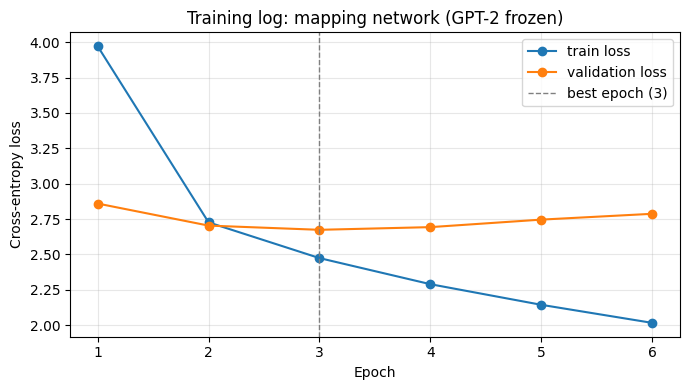

,epoch,train_loss,val_loss,val_ppl,lr,time_s,best
0,1,3.9719,2.8593,17.45,1.98e-04,27.6,*
1,2,2.7263,2.7034,14.93,1.88e-04,28.3,*
2,3,2.4736,2.6736,14.49,1.77e-04,28.9,*
3,4,2.2891,2.6926,14.77,1.67e-04,29.6,
4,5,2.1433,2.7457,15.58,1.56e-04,30.2,
5,6,2.0156,2.7868,16.23,1.46e-04,30.8,


In [11]:
log_df = pd.DataFrame(log)
log_df.to_csv(f'{OUT_DIR}/training_log.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(log_df['epoch'], log_df['train_loss'], marker='o', label='train loss')
ax.plot(log_df['epoch'], log_df['val_loss'], marker='o', label='validation loss')
ax.axvline(best_epoch, color='gray', ls='--', lw=1, label=f'best epoch ({best_epoch})')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy loss'); ax.set_title('Training log: mapping network (GPT-2 frozen)')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/loss_curve.png', dpi=150); plt.show()

log_df

## 7. Sanity check
Greedy decoding on 3 validation images with the best checkpoint, only to confirm that training produces sensible captions.

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded epoch 3 | val loss 2.6736
image 7991
  reference: a plate topped with baby carrots and beans next to a peeler
  generated: a bowl of steamed broccoli with a spoon

image 11760
  reference: a group of zebras walking away from trees
  generated: a group of zebras are standing in a field

image 15660
  reference: there is a man on a surf board in the ocean
  generated: a person is standing on a surfboard



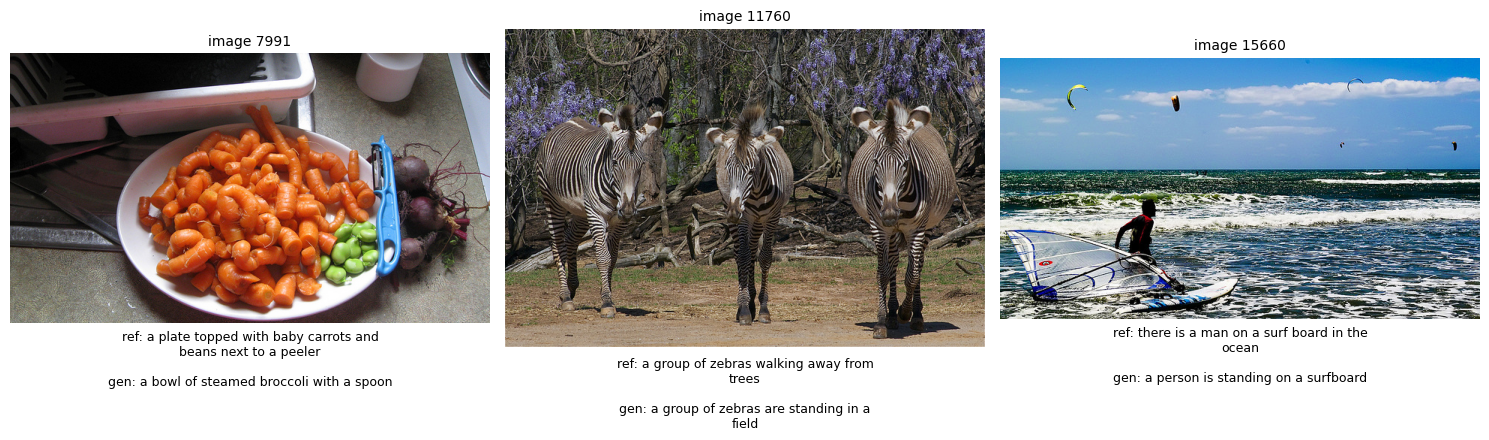

In [12]:
best_model, ckpt = load_model(CKPT_PATH, device)
print('loaded epoch', ckpt['epoch'], '| val loss', round(ckpt['val_loss'], 4))

@torch.no_grad()
def greedy_caption(m, clip_emb, max_len=MAX_LEN):
    embeds = m.get_prefix(clip_emb.unsqueeze(0).to(device))
    wte, out_ids = m.gpt.get_input_embeddings(), []
    for _ in range(max_len):
        next_id = m.gpt(inputs_embeds=embeds).logits[0, -1].argmax().item()
        if next_id == tokenizer.eos_token_id:
            break
        out_ids.append(next_id)
        embeds = torch.cat([embeds, wte(torch.tensor([[next_id]], device=device))], dim=1)
    return tokenizer.decode(out_ids).strip()

import requests, textwrap
from io import BytesIO
from PIL import Image

def load_coco_image(image_id):
    local = f'/content/coco/val2017/{image_id:012d}.jpg'
    if os.path.exists(local):
        return Image.open(local).convert('RGB')
    url = f'http://images.cocodataset.org/val2017/{image_id:012d}.jpg'
    return Image.open(BytesIO(requests.get(url, timeout=30).content)).convert('RGB')

val_imgs = df[df['split'] == 'val'].drop_duplicates('image_id').head(3)

fig, axes = plt.subplots(1, len(val_imgs), figsize=(5 * len(val_imgs), 5.5))
for ax, (_, r) in zip(axes, val_imgs.iterrows()):
    gen = greedy_caption(best_model, embs[id2row[r['image_id']]])
    ax.imshow(load_coco_image(r['image_id']))
    ax.axis('off')
    ax.set_title(f"image {r['image_id']}", fontsize=10)
    text = 'ref: ' + '\n'.join(textwrap.wrap(r['caption'], 40)) + '\n\ngen: ' + '\n'.join(textwrap.wrap(gen, 40))
    ax.text(0.5, -0.03, text, transform=ax.transAxes, ha='center', va='top', fontsize=9)
    print(f"image {r['image_id']}\n  reference: {r['caption']}\n  generated: {gen}\n")
plt.tight_layout()
plt.show()

## 8. Save the result
Copies the model code next to the checkpoint so the generation part can load the model:

```python
model, ckpt = load_model('/content/drive/MyDrive/IE7615_generative/milestone2/mapping_net.pt', device)
prefix = model.get_prefix(clip_emb)   # (B, 10, 768) -> GPT-2 inputs_embeds
```

In [13]:
summary = {'best_epoch': best_epoch, 'best_val_loss': round(best_val, 4),
           'best_val_ppl': round(math.exp(best_val), 2), 'epochs_run': len(log),
           'trainable_params': n_train,
           'config': dict(prefix_len=PREFIX_LEN, freeze_gpt=FREEZE_GPT, normalize_emb=NORMALIZE_EMB,
                          max_len=MAX_LEN, batch_size=BATCH_SIZE, lr=LR, warmup=WARMUP_STEPS,
                          weight_decay=WEIGHT_DECAY, dropout=DROPOUT, patience=PATIENCE, seed=SEED)}
with open(f'{OUT_DIR}/training_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print('\nfiles in', OUT_DIR)
for fn in sorted(os.listdir(OUT_DIR)):
    print(f'  {fn:<24} {os.path.getsize(f"{OUT_DIR}/{fn}") / 1e6:7.2f} MB')

{
  "best_epoch": 3,
  "best_val_loss": 2.6736,
  "best_val_ppl": 14.49,
  "epochs_run": 6,
  "trainable_params": 31468800,
  "config": {
    "prefix_len": 10,
    "freeze_gpt": true,
    "normalize_emb": true,
    "max_len": 30,
    "batch_size": 32,
    "lr": 0.0002,
    "warmup": 100,
    "weight_decay": 0.01,
    "dropout": 0.1,
    "patience": 3,
    "seed": 42
  }
}

files in /content/drive/MyDrive/IE7615_generative/milestone2
  caption_samples.png         7.76 MB
  generated_captions.csv      0.00 MB
  loss_curve.png              0.07 MB
  mapping_net.pt            125.88 MB
  training_log.csv            0.00 MB
  training_summary.json       0.00 MB


## 9. Load the trained model

Load the best checkpoint with lowest val loss saved in Section 5. Only the mapping network was trained, not GPT-2.

In [14]:
CKPT_PATH = f'{OUT_DIR}/mapping_net.pt'

if os.path.exists(CKPT_PATH):
  model, ckpt = load_model(CKPT_PATH, device)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

## 10. Caption Generation

Generate a caption from a CLIP image embedding with three decoding strategies : greedy, beam search(5 beams), and nucleus sampling(top-p=0.9). No_repeat optionally blocks repeated n-grams.

In [19]:
def generate_caption(img_emb, method = 'greedy', no_repeat = 0):
  with torch.no_grad():
    prefix = model.get_prefix(img_emb.to(device).float())
    options = {
        'greedy' : dict(do_sample = False, num_beams = 1),
        'beam' : dict(do_sample = False, num_beams = 5),
        'nucleus' : dict(do_sample = True, top_p = 0.9),
    }[method]
    out = model.gpt.generate(inputs_embeds = prefix,
                        attention_mask = torch.ones(prefix.shape[:2], device = device),
                        max_new_tokens = MAX_LEN,
                        eos_token_id = tokenizer.eos_token_id,
                        pad_token_id = tokenizer.eos_token_id,
                        no_repeat_ngram_size = no_repeat,
                        **options)


  text = tokenizer.decode(out[0], skip_special_tokens=True)
  return text.split('\n')[0].strip()

## 11. Initial Test

Generate captions for 10 test images with each decoding strategy and compare them with the five reference captions.

In [20]:
torch.manual_seed(42) # For nucleus option(do_sample = True)

test_ids = df[df['split'] == 'test']['image_id'].unique()[:10]

for i in test_ids:
    emb = embs[id2row[i]].unsqueeze(0)
    refs = df[df['image_id'] == i]['caption'].tolist()    # all five
    print(i)
    for r in refs:
        print('  ref     :', r)
    for m in ['greedy', 'beam', 'nucleus']:
        print(f'  {m:8s}:', generate_caption(emb, m))
    print()

4134
  ref     : a man is shaking hands with another man
  ref     : two men shake hands at a formal dinner gathering
  ref     : two men standing next to each other holding hands
  ref     : two men are shaking hands at a social gathering
  ref     : two men shaking hands after a dinner speech
  greedy  : a man and a woman in a man's man's man's man's man's man's man's man's man's man's man's man
  beam    : a man and a woman in a man's man's man's man's man's man's man's man's man's man's man's man
  nucleus : the man and the woman being in a thong

7108
  ref     : a herd of elephants walking away from a watering hole
  ref     : a close up from knees up front view of an elephant with trunk forward, outside on dirt, with other elephants, grass, bushes and white-blue sky
  ref     : an elephant is seen head on amongst other elephants
  ref     : elephants walking along a dirt path next to water
  ref     : several elephants walking together in a line near water
  greedy  : a group of

## 12. Baseline Test with repetition control(no_repeat_ngram_size = 3)  

Same 10 test images and seed as above, but any three-word phrase can appear only once in a caption. This targets the repetition loops seen in greedy and beam search in the initial test.


In [21]:
torch.manual_seed(42)
rows = []

for i in test_ids:
    emb = embs[id2row[i]].unsqueeze(0)
    refs = df[df['image_id'] == i]['caption'].tolist()
    print(i)
    for r in refs:
        print('ref     :', r)
    for m in ['greedy', 'beam', 'nucleus']:
        cap = generate_caption(emb, m, no_repeat=3)
        print(f'{m:8s}:', cap)
        rows.append({'image_id': i, 'method': m, 'no_repeat': 3, 'caption': cap})
    print()

pd.DataFrame(rows).to_csv(f'{OUT_DIR}/generated_captions.csv', index=False)
print('saved', len(rows), 'captions')

4134
ref     : a man is shaking hands with another man
ref     : two men shake hands at a formal dinner gathering
ref     : two men standing next to each other holding hands
ref     : two men are shaking hands at a social gathering
ref     : two men shaking hands after a dinner speech
greedy  : a man and a woman in a man's man's chair


/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1477: UserWarning: Passing `no_repeat_ngram_size` with `inputs_embeds` and without `input_ids` to `generate` will apply n-gram constraints only to newly generated tokens, not to the prompt.
  warnings.warn(


beam    : a man and a woman sitting on a table
nucleus : the man and the woman being in a thong

7108
ref     : a herd of elephants walking away from a watering hole
ref     : a close up from knees up front view of an elephant with trunk forward, outside on dirt, with other elephants, grass, bushes and white-blue sky
ref     : an elephant is seen head on amongst other elephants
ref     : elephants walking along a dirt path next to water
ref     : several elephants walking together in a line near water
greedy  : a group of elephants standing in a field
beam    : a group of elephants standing in front of a fence
nucleus : a young elephant walking in a field

7784
ref     : this is a large kite flying high in the sky
ref     : a large orange and white kite flying in a blue sky
ref     : there is a colorful parachute in the sky
ref     : a large white and red parasail in the blue sky
ref     : a red and white parachute is in the sky
greedy  : a man is flying a kite with a kilt
beam    : a 

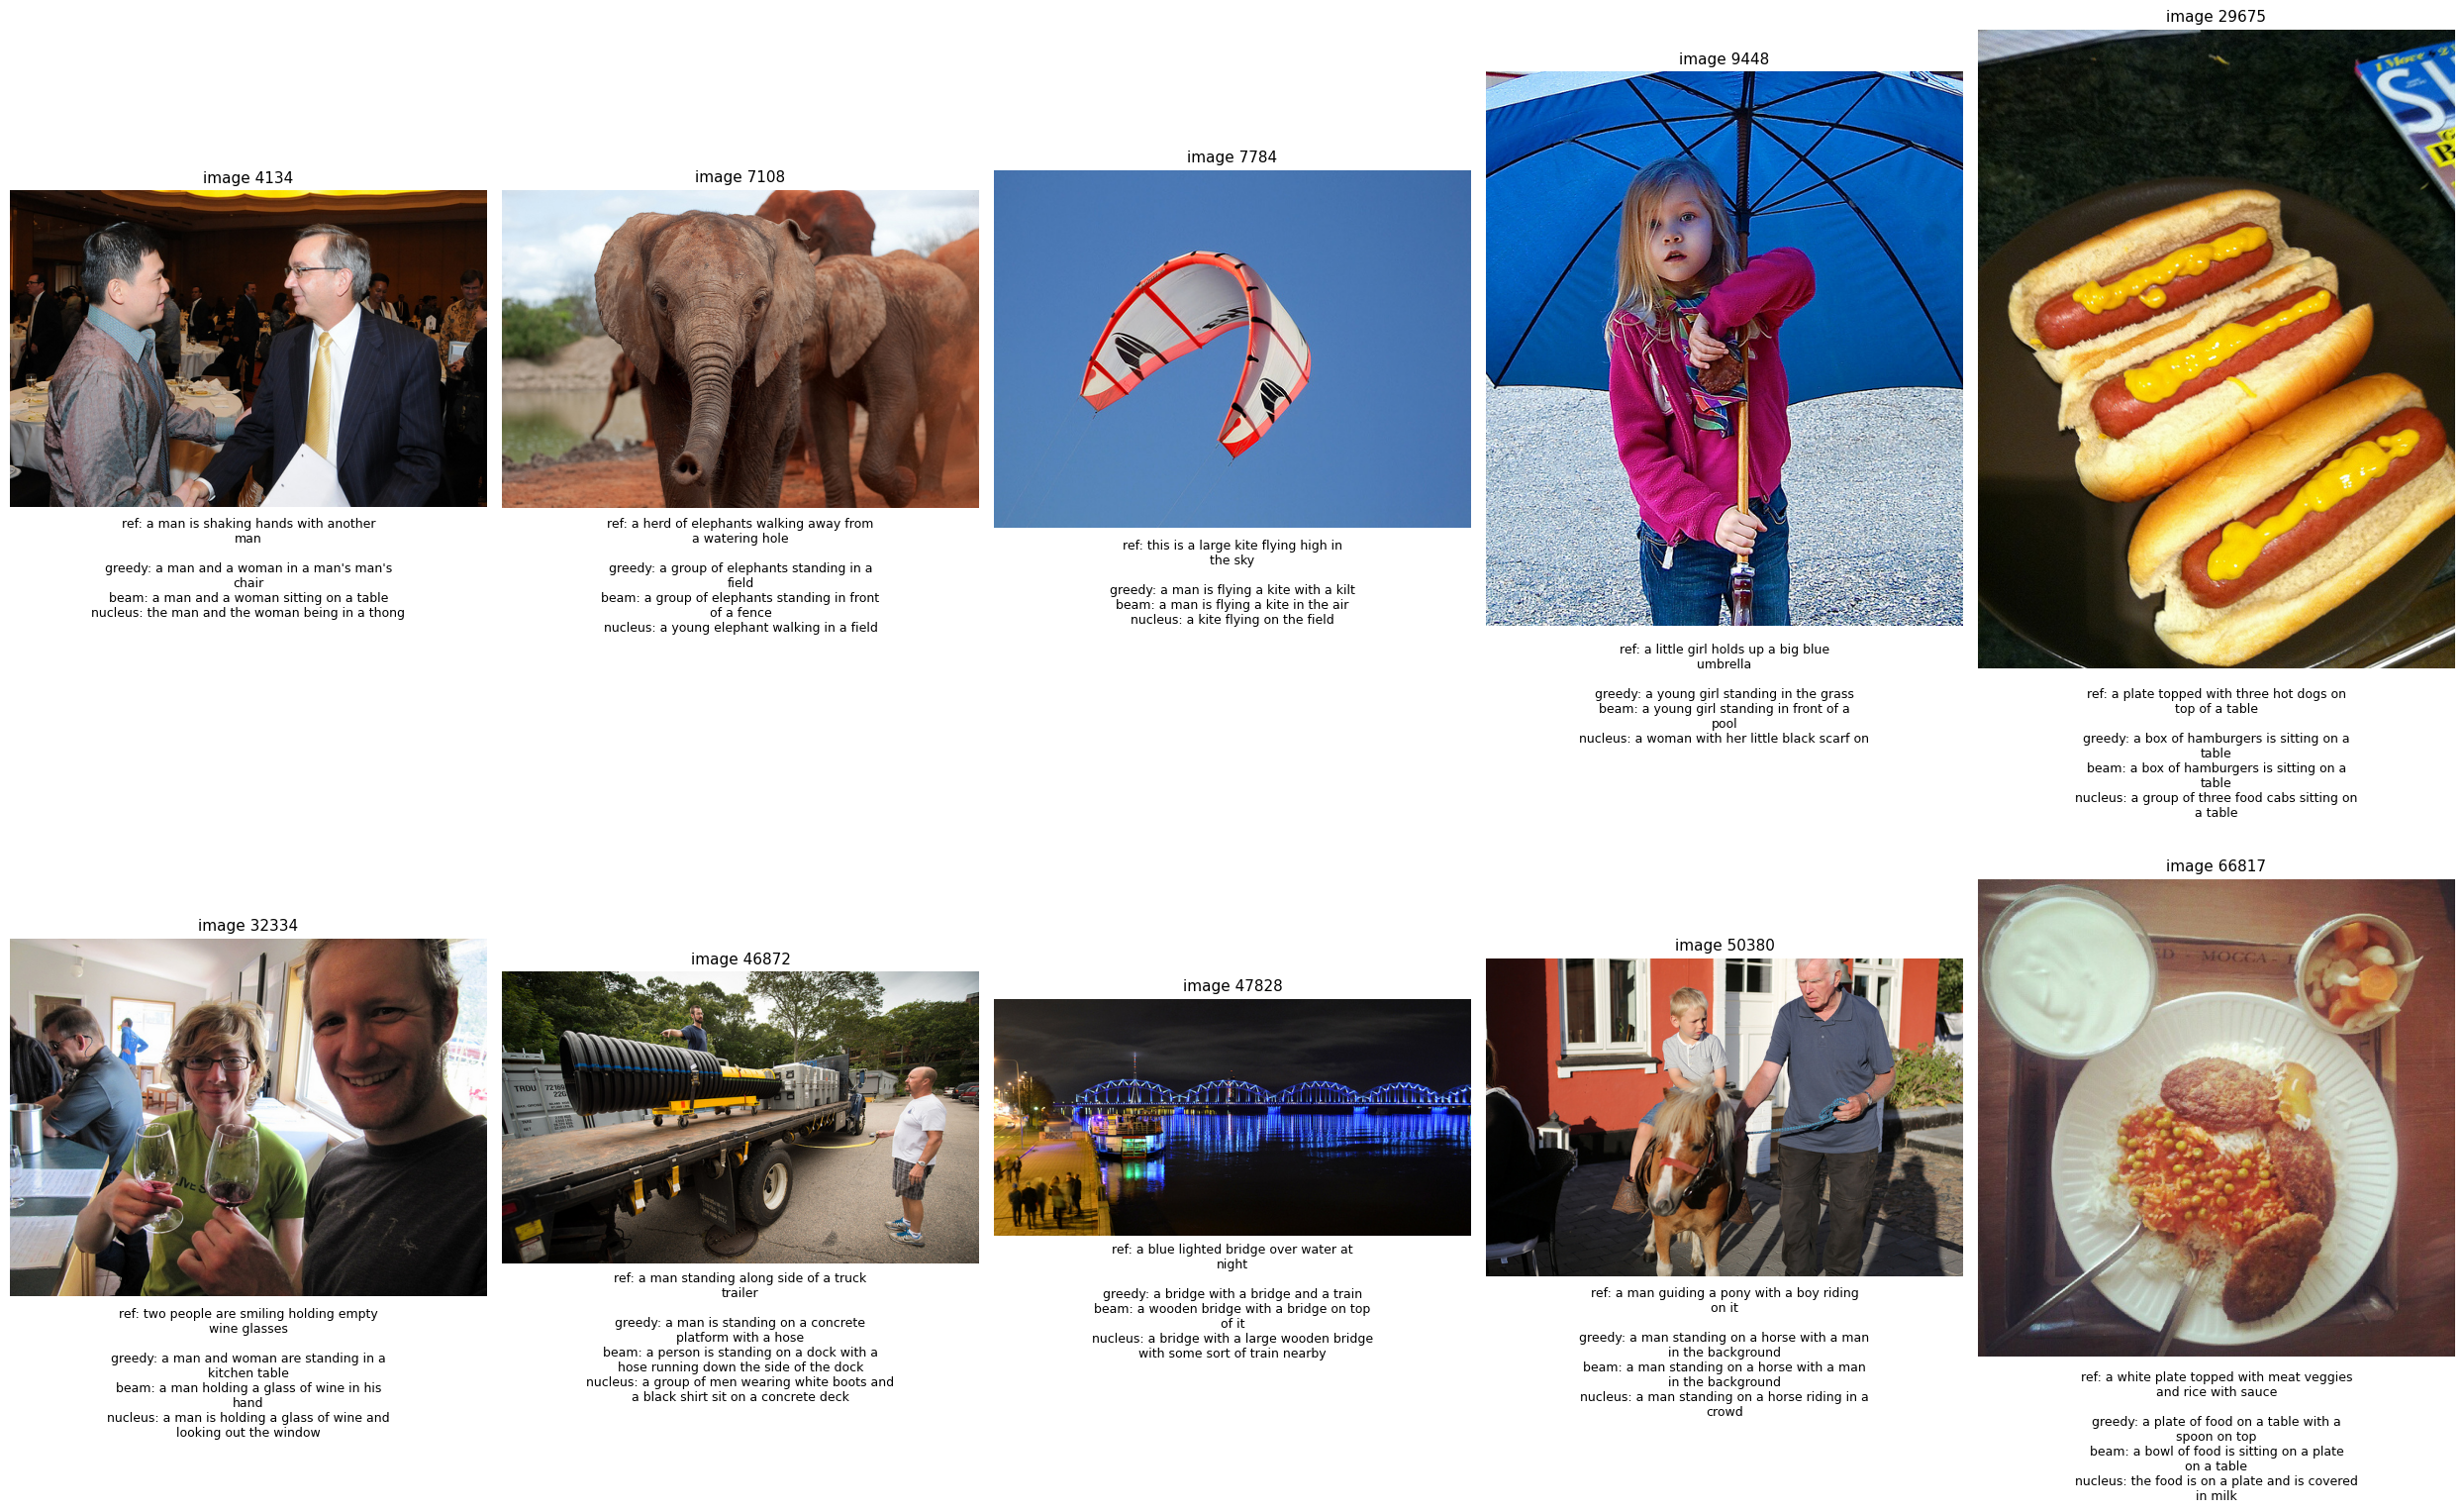

In [22]:
import requests, textwrap
from io import BytesIO
from PIL import Image

def load_coco_image(image_id):
    url = f'http://images.cocodataset.org/val2017/{int(image_id):012d}.jpg'
    return Image.open(BytesIO(requests.get(url, timeout=30).content)).convert('RGB')

gen = pd.read_csv(f'{OUT_DIR}/generated_captions.csv')
gen = gen[gen['no_repeat'] == 3]       # with repetition control
wrap = lambda s: '\n'.join(textwrap.wrap(str(s), 38))

fig, axes = plt.subplots(2, 5, figsize=(25, 16))
for ax, i in zip(axes.flat, test_ids):
    ax.imshow(load_coco_image(i))
    ax.axis('off')
    ax.set_title(f'image {i}', fontsize=11)

    ref  = df[df['image_id'] == i]['caption'].iloc[0]
    caps = gen[gen['image_id'] == i].set_index('method')['caption']
    text = f'ref: {wrap(ref)}\n\n' + '\n'.join(f'{m}: {wrap(caps[m])}' for m in ['greedy', 'beam', 'nucleus'])
    ax.text(0.5, -0.03, text, transform=ax.transAxes, ha='center', va='top', fontsize=9)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/caption_samples.png', dpi=150, bbox_inches='tight')
plt.show()

> Observation : The model tends to capture the main subject and scene of each image, but it misses details such as actions(shaking hands), objects(umbrella in 9448), object count(three hot dogs in 29675).

> This may come from two sources : (1) the CLIP embedding summarizes the image into a single 512-dimensional vector, which can lose fine details, and (2) the mapping network was trained with only 4,000 caption pairs and may not pass enough image information to GPT-2.

> In the initial test, greedy decoding and beam search sometimes fell into repetition loops (a man and a woman in a man’s man’s man’s… in 4134) and ran until the 30-token limit. Nucleus sampling was less affected because it samples from the probability distribution.

> Setting no_repeat_ngram_size = 3, which blocks any 3-word sequence from appearing twice, removed these loops, and the captions ended naturally at the end-of-sequence token(beam search in 4134: “a man and a woman sitting on a table”). The trade-off is that a blocked phrase can be replaced with a wrong word: in 7784, greedy decoding produced “a man is flying a kite with a kilt” instead. We therefore use this setting as our baseline.

> Because GPT-2 is frozen, it sometimes produced a line break instead of the end-of-sequence token and continued with web-like text from its pretraining data (e.g., “RAW Paste Data…” after one caption). We keep only the first line of each generated caption.
